<a href="https://colab.research.google.com/github/PaoloniCoder/MozartAI/blob/M2-foto/notebook/m2_righi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys, os, glob
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

UTENTE = 'martinopaoloni-ux'
BRANCH = 'M2-foto'

!rm -rf /content/MozartAI
!git clone -b {BRANCH} https://github.com/{UTENTE}/MozartAI.git /content/MozartAI
sys.path.insert(0, '/content/MozartAI/src')
from preprocessing import foto_a_righi
print("Importato:", foto_a_righi)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/MozartAI'...
remote: Enumerating objects: 79, done.
remote: Counting objects: 100% (79/79), done.
remote: Compressing objects: 100% (73/73), done.
remote: Total 79 (delta 33), reused 9 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (79/79), 7.19 MiB | 8.11 MiB/s, done.
Resolving deltas: 100% (33/33), done.
Importato: <function foto_a_righi at 0x7c89adb158a0>


In [2]:
CARTELLA = '/content/drive/MyDrive/MozartAI/Foto Prova'
FOTO = sorted(f for ext in ('jpg', 'jpeg', 'png') for f in glob.glob(f'{CARTELLA}/*.{ext}'))

risultati = {}
for f in FOTO:
    righi = foto_a_righi(f, margine=2.0)
    risultati[os.path.basename(f)] = righi
    print(f"{os.path.basename(f):32s} -> {len(righi)} righi", [r.shape for r in righi])

IMG_3276.jpeg                    -> 1 righi [(165, 1939)]
IMG_3277.jpeg                    -> 1 righi [(151, 1942)]
IMG_3278.jpeg                    -> 1 righi [(209, 1906)]
IMG_3279.jpeg                    -> 2 righi [(166, 1937), (161, 1913)]
IMG_3280.jpeg                    -> 2 righi [(210, 1726), (208, 1894)]


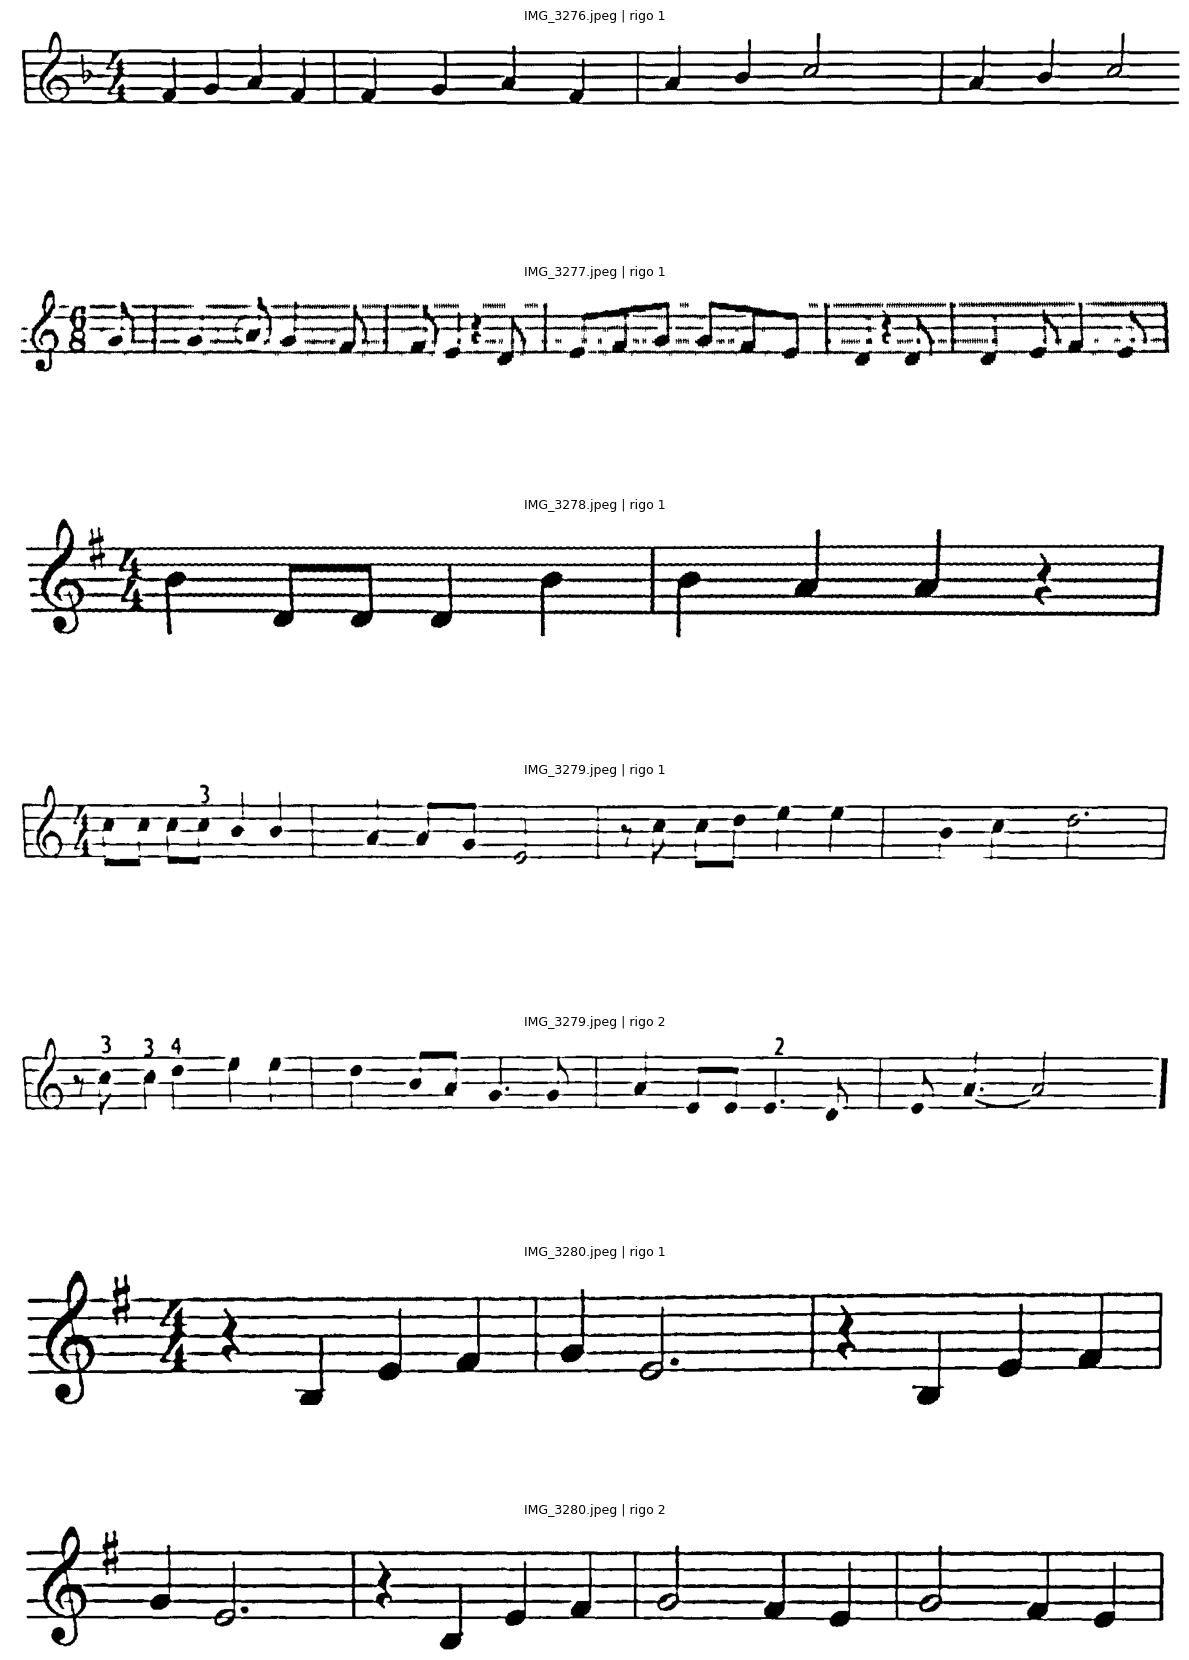

In [3]:
tutti = [(nome, i + 1, r) for nome, righi in risultati.items() for i, r in enumerate(righi)]
fig, assi = plt.subplots(len(tutti), 1, figsize=(12, 2.6 * len(tutti)))
for ax, (nome, i, r) in zip(assi, tutti):
    ax.imshow(r, cmap='gray'); ax.set_title(f"{nome} | rigo {i}", fontsize=9); ax.axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/MozartAI/risultati_m2_righi.png', dpi=110)
plt.show()

In [4]:
import tarfile, numpy as np
from PIL import Image
from preprocessing import trova_pentagrammi

ARCHIVE = '/content/drive/MyDrive/MozartAI/data/primus.tgz'
esempi = []
with tarfile.open(ARCHIVE, 'r:gz') as tar:
    for m in tar:
        nome = os.path.basename(m.name)
        if nome.endswith('.png') and not nome.startswith('._'):
            esempi.append(np.array(Image.open(tar.extractfile(m)).convert('L')))
            if len(esempi) == 30:
                break

misure = []
for img in esempi:
    b = np.where(img < 128, 0, 255).astype(np.uint8)          # binaria: inchiostro 0
    pent = trova_pentagrammi(b)
    if len(pent) == 1:
        p = pent[0]
        sopra = p['y0'] / p['s']                              # spazio sopra la prima riga
        sotto = (b.shape[0] - p['y1']) / p['s']               # spazio sotto l'ultima riga
        misure.append((sopra, sotto))
        print(f"altezza={b.shape[0]:3d}  s={p['s']:.1f}  sopra={sopra:.1f}  sotto={sotto:.1f}")

misure = np.array(misure)
print(f"\nSu {len(misure)} esempi: sopra mediana={np.median(misure[:,0]):.1f}  sotto mediana={np.median(misure[:,1]):.1f}")

altezza=155  s=18.0  sopra=2.6  sotto=2.1
altezza=126  s=18.0  sopra=1.4  sotto=1.6
altezza=119  s=18.0  sopra=0.6  sotto=2.1
altezza=155  s=18.0  sopra=2.6  sotto=2.1
altezza=139  s=18.0  sopra=2.1  sotto=1.7
altezza=138  s=18.0  sopra=1.8  sotto=1.8
altezza=171  s=18.0  sopra=3.3  sotto=2.2
altezza=126  s=18.0  sopra=1.4  sotto=1.6
altezza=111  s=18.0  sopra=1.1  sotto=1.1
altezza=155  s=18.0  sopra=2.6  sotto=2.1
altezza=147  s=18.0  sopra=2.1  sotto=2.1
altezza=157  s=18.0  sopra=1.4  sotto=3.3
altezza=142  s=18.0  sopra=1.6  sotto=2.3
altezza=149  s=18.0  sopra=1.9  sotto=2.3
altezza=128  s=18.0  sopra=1.4  sotto=1.7
altezza=139  s=18.0  sopra=2.1  sotto=1.6
altezza=164  s=18.0  sopra=2.8  sotto=2.3
altezza=145  s=18.0  sopra=2.5  sotto=1.6
altezza=164  s=18.0  sopra=2.1  sotto=3.1
altezza=164  s=18.0  sopra=2.6  sotto=2.6
altezza=129  s=18.0  sopra=1.1  sotto=2.1
altezza=164  s=18.0  sopra=1.6  sotto=3.6
altezza=128  s=18.0  sopra=1.1  sotto=2.1
altezza=130  s=18.0  sopra=1.6  so